In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os

# --- EDIT THIS: apni ZIP file ka path daalein ---
ZIP_PATH = "/content/drive/MyDrive/ricedataset.zip"

# Verify ZIP exists
print("ZIP exists:", os.path.exists(ZIP_PATH))
print("ZIP size  :", round(os.path.getsize(ZIP_PATH) / (1024**3), 2), "GB")

ZIP exists: True
ZIP size  : 0.49 GB


In [3]:
import zipfile, time

# Local extraction folder (Colab ke local SSD par — Drive se 10x faster)
EXTRACT_DIR = "/content/rice_dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

start = time.time()
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
print(f"✅ Extracted in {time.time()-start:.1f} sec")

✅ Extracted in 11.2 sec


In [4]:
# ==============================================================================
# IMPORTS
# ==============================================================================
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, LeakyReLU, ReLU, Add, Concatenate,
    MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Reshape, Multiply
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, accuracy_score, confusion_matrix
)


In [5]:

# ==============================================================================
# REPRODUCIBILITY — Fix all random seeds
# ==============================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [6]:

# ==============================================================================
# CONFIGURATION
# ==============================================================================
IMG_SIZE = 224
IMG_CHANNELS = 3           # RGB
BATCH_SIZE = 32
EPOCHS = 120
NUM_CLASSES = 12

# Paths (Colab)
BASE_DIR = "/content/rice_dataset/dataset_split"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR   = os.path.join(BASE_DIR, "validation")
TEST_DIR  = os.path.join(BASE_DIR, "test")
# Save paths
MODEL_SAVE_PATH  = "/content/drive/MyDrive/hybrid_rds_best.h5"
HISTORY_SAVE_PATH = "/content/drive/MyDrive/history_hybrid_rds.json"
CM_SAVE_PATH     = "/content/drive/MyDrive/cm_hybrid_rds.png"
CURVES_SAVE_PATH = "/content/drive/MyDrive/curves_hybrid_rds.png"


In [7]:

# ==============================================================================
# DATA GENERATORS
# ==============================================================================
# Augmentation pipeline matches the oversampling pipeline (Albumentations was
# used offline; this Keras pipeline mimics it during training for consistency).

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,               # ±20°
    zoom_range=0.10,                 # ±10%
    width_shift_range=0.08,          # ±8%
    height_shift_range=0.08,         # ±8%
    horizontal_flip=True,            # p = 0.5
    brightness_range=[0.88, 1.12],   # ±12%
    fill_mode='reflect'
)

val_datagen  = ImageDataGenerator(rescale=1.0 / 255.0)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
NUM_CLASSES = len(class_names)

print("=" * 78)
print("DATASET SUMMARY")
print("=" * 78)
print(f"Classes ({NUM_CLASSES}):")
for i, name in enumerate(class_names, 1):
    print(f"  {i:2d}. {name}")
print(f"\nTrain images:       {train_generator.samples}")
print(f"Validation images:  {val_generator.samples}")
print(f"Test images:        {test_generator.samples}")
print("=" * 78)


Found 3658 images belonging to 12 classes.
Found 455 images belonging to 12 classes.
Found 464 images belonging to 12 classes.
DATASET SUMMARY
Classes (12):
   1. bacterial_leaf_blight
   2. brown_spot
   3. healthy_leaf
   4. hispa
   5. leaf_blast
   6. leaf_scald
   7. narrow_brown_spot
   8. non_leaf
   9. ragged_stunt_virus
  10. sheath_rot
  11. stem_rot
  12. tungro

Train images:       3658
Validation images:  455
Test images:        464


In [8]:

# ==============================================================================
# MODEL BLOCKS
# ==============================================================================

def residual_block(x, filters):
    """
    Residual Block (He et al., 2016 — ResNet style).

    Structure:
        shortcut: 1×1 conv (channel matching)
        main:     3×3 conv → BN → LeakyReLU → 3×3 conv → BN
        output:   Add([main, shortcut]) → LeakyReLU
    """
    # Shortcut path
    shortcut = Conv2D(filters, kernel_size=1, padding="same")(x)

    # Main path
    x = Conv2D(filters, kernel_size=3, padding="same")(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.1)(x)

    x = Conv2D(filters, kernel_size=3, padding="same")(x)
    x = BatchNormalization()(x)

    # Merge
    x = Add()([x, shortcut])
    x = LeakyReLU(alpha=0.1)(x)

    return x


def dense_block(x, growth_rate=32):
    """
    Dense Block (Huang et al., 2017 — DenseNet style).

    Structure:
        Two 3×3 convolutions, each concatenated with the running feature map.
        Growth rate g = 32 channels per convolution.
    """
    # Layer 1
    y = Conv2D(growth_rate, kernel_size=3, padding="same", activation="relu")(x)
    x = Concatenate()([x, y])

    # Layer 2
    y = Conv2D(growth_rate, kernel_size=3, padding="same", activation="relu")(x)
    x = Concatenate()([x, y])

    return x


def se_block(x, reduction=4):
    """
    Squeeze-and-Excitation Block (Hu et al., 2018 — channel attention).

    Structure:
        Squeeze:    Global Average Pooling → (C,)
        Excitation: Dense(C/r) → ReLU → Dense(C) → Sigmoid
        Scale:      x ⊙ attention
    """
    filters = x.shape[-1]

    # Squeeze
    se = GlobalAveragePooling2D()(x)

    # Excitation
    se = Dense(filters // reduction, activation="relu")(se)
    se = Dense(filters, activation="sigmoid")(se)

    # Reshape to (1, 1, C) for broadcasting
    se = Reshape((1, 1, filters))(se)

    # Scale
    x = Multiply()([x, se])

    return x



In [9]:

# ==============================================================================
# BUILD HYBRID MODEL
# ==============================================================================

def build_hybrid_model(input_shape=(IMG_SIZE, IMG_SIZE, IMG_CHANNELS),
                        num_classes=NUM_CLASSES):
    """Build the Hybrid (Residual + Dense + SE) CNN."""

    inputs = Input(shape=input_shape, name="input_image")

    # ---- Stem ----
    x = Conv2D(64, kernel_size=3, padding="same", name="stem_conv")(inputs)
    x = BatchNormalization(name="stem_bn")(x)
    x = LeakyReLU(alpha=0.1, name="stem_activation")(x)

    # ---- Block 1: Residual (64) ----
    x = residual_block(x, 64)
    x = MaxPooling2D(pool_size=2, name="block1_pool")(x)

    # ---- Block 2: Dense + SE ----
    x = dense_block(x, growth_rate=32)
    x = se_block(x, reduction=4)
    x = MaxPooling2D(pool_size=2, name="block2_pool")(x)

    # ---- Block 3: Residual (128) ----
    x = residual_block(x, 128)
    x = MaxPooling2D(pool_size=2, name="block3_pool")(x)

    # ---- Block 4: Dense + SE ----
    x = dense_block(x, growth_rate=32)
    x = se_block(x, reduction=4)
    x = MaxPooling2D(pool_size=2, name="block4_pool")(x)

    # ---- Block 5: Residual (256), no pooling ----
    x = residual_block(x, 256)

    # ---- Classification Head ----
    x = GlobalAveragePooling2D(name="gap")(x)

    x = Dense(512, name="fc1")(x)
    x = BatchNormalization(name="fc1_bn")(x)
    x = LeakyReLU(alpha=0.1, name="fc1_activation")(x)
    x = Dropout(0.5, name="fc1_dropout")(x)

    x = Dense(256, name="fc2")(x)
    x = LeakyReLU(alpha=0.1, name="fc2_activation")(x)
    x = Dropout(0.3, name="fc2_dropout")(x)

    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)

    model = Model(inputs=inputs, outputs=outputs, name="Hybrid_RDS")

    return model


# ---- Instantiate ----
model = build_hybrid_model()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [10]:

# ==============================================================================
# COMPILE MODEL
# ==============================================================================
optimizer = AdamW(learning_rate=1e-4, weight_decay=1e-4)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

print("\n" + "=" * 78)
print("MODEL SUMMARY")
print("=" * 78)
model.summary()




MODEL SUMMARY


Model: "Hybrid_RDS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 224, 224,  │      1,792 │ input_image[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 224, 224,  │        256 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 224, 224,  │          0 │ stem_bn[0][0]     │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │     36,928 │ stem_activation[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │     36,928 │ leaky_re_lu[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      4,160 │ stem_activation[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 224, 224,  │          0 │ add[0][0]         │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ leaky_re_lu_1[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     18,464 │ block1_pool[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 112, 112,  │          0 │ block1_pool[0][0… │
│ (Concatenate)       │ 96)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │     27,680 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 112, 112,  │          0 │ concatenate[0][0

 Total params: 1,901,660 (7.25 MB)

 Trainable params: 1,898,716 (7.24 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [11]:
# ==============================================================================
# CLASS WEIGHTS (balanced)
# ==============================================================================
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights_array))

print("\n" + "=" * 78)
print("CLASS WEIGHTS")
print("=" * 78)
for i, name in enumerate(class_names):
    print(f"  {name:30s}: {class_weights[i]:.4f}")



CLASS WEIGHTS
  bacterial_leaf_blight         : 1.0548
  brown_spot                    : 0.9739
  healthy_leaf                  : 0.8760
  hispa                         : 1.0887
  leaf_blast                    : 0.9072
  leaf_scald                    : 1.0696
  narrow_brown_spot             : 0.9322
  non_leaf                      : 0.8468
  ragged_stunt_virus            : 1.0887
  sheath_rot                    : 1.0887
  stem_rot                      : 1.0887
  tungro                        : 1.0887


In [14]:

# ==============================================================================
# CALLBACKS
# ==============================================================================
callbacks = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=10,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=25,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=MODEL_SAVE_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]



In [15]:

# ==============================================================================
# TRAIN MODEL
# ==============================================================================
print("\n" + "=" * 78)
print("STARTING TRAINING")
print("=" * 78)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "=" * 78)
print("TRAINING COMPLETE")
print("=" * 78)


STARTING TRAINING
Epoch 1/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3761 - loss: 2.0721
Epoch 1: val_loss improved from None to 2.61054, saving model to /content/drive/MyDrive/hybrid_rds_best.h5



Epoch 1: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.4855 - loss: 1.7545 - val_accuracy: 0.0923 - val_loss: 2.6105 - learning_rate: 1.0000e-04
Epoch 2/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 904ms/step - accuracy: 0.6333 - loss: 1.4073
Epoch 2: val_loss did not improve from 2.61054
115/115 ━━━━━━━━━━━━━━━━━━━━ 109s 944ms/step - accuracy: 0.6616 - loss: 1.3592 - val_accuracy: 0.0923 - val_loss: 2.8456 - learning_rate: 1.0000e-04
Epoch 3/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.7168 - loss: 1.2560
Epoch 3: val_loss did not improve from 2.61054
115/115 ━━━━━━━━━━━━━━━━━━━━ 104s 906ms/step - accuracy: 0.7080 - loss: 1.2558 - val_accuracy: 0.1055 - val_loss: 2.8212 - learning_rate: 1.0000e-04
Epoch 4/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 871ms/step - accuracy: 0.7595 - loss: 1.1552
Epoch 4: val_loss improved from 2.61054 to 2.40248, saving model to /content/drive/MyDrive/hybrid_rds_best.h5



Epoch 4: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 107s 930ms/step - accuracy: 0.7551 - loss: 1.1525 - val_accuracy: 0.3253 - val_loss: 2.4025 - learning_rate: 1.0000e-04
Epoch 5/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 877ms/step - accuracy: 0.7846 - loss: 1.0882
Epoch 5: val_loss improved from 2.40248 to 1.66232, saving model to /content/drive/MyDrive/hybrid_rds_best.h5



Epoch 5: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 107s 928ms/step - accuracy: 0.7849 - loss: 1.0813 - val_accuracy: 0.5011 - val_loss: 1.6623 - learning_rate: 1.0000e-04
Epoch 6/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 903ms/step - accuracy: 0.8017 - loss: 1.0567
Epoch 6: val_loss improved from 1.66232 to 1.27523, saving model to /content/drive/MyDrive/hybrid_rds_best.h5



Epoch 6: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 110s 954ms/step - accuracy: 0.8037 - loss: 1.0455 - val_accuracy: 0.6396 - val_loss: 1.2752 - learning_rate: 1.0000e-04
Epoch 7/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 862ms/step - accuracy: 0.8242 - loss: 0.9940
Epoch 7: val_loss improved from 1.27523 to 1.05463, saving model to /content/drive/MyDrive/hybrid_rds_best.h5



Epoch 7: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 137s 915ms/step - accuracy: 0.8327 - loss: 0.9733 - val_accuracy: 0.8044 - val_loss: 1.0546 - learning_rate: 1.0000e-04
Epoch 8/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 877ms/step - accuracy: 0.8421 - loss: 0.9639
Epoch 8: val_loss improved from 1.05463 to 0.83835, saving model to /content/drive/MyDrive/hybrid_rds_best.h5


... (13 outputs left out)


Epoch 63: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 108s 933ms/step - accuracy: 0.9841 - loss: 0.6184 - val_accuracy: 0.9868 - val_loss: 0.6069 - learning_rate: 9.0000e-06
Epoch 64/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 861ms/step - accuracy: 0.9825 - loss: 0.6197
Epoch 64: val_loss did not improve from 0.60694
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 911ms/step - accuracy: 0.9800 - loss: 0.6207 - val_accuracy: 0.9802 - val_loss: 0.6148 - learning_rate: 9.0000e-06
Epoch 65/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 876ms/step - accuracy: 0.9800 - loss: 0.6246
Epoch 65: val_loss did not improve from 0.60694
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 916ms/step - accuracy: 0.9817 - loss: 0.6207 - val_accuracy: 0.9714 - val_loss: 0.6254 - learning_rate: 9.0000e-06
Epoch 66/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 879ms/step - accuracy: 0.9846 - loss: 0.6177
Epoch 66: val_loss did not improve from 0.60694
115/115 ━━━━━━━━━━━━━━━━━━━━ 106s 925ms/step - accuracy: 0.98


Epoch 70: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 109s 943ms/step - accuracy: 0.9847 - loss: 0.6168 - val_accuracy: 0.9890 - val_loss: 0.6013 - learning_rate: 9.0000e-06
Epoch 71/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 886ms/step - accuracy: 0.9866 - loss: 0.6150
Epoch 71: val_loss did not improve from 0.60128
115/115 ━━━━━━━━━━━━━━━━━━━━ 107s 929ms/step - accuracy: 0.9866 - loss: 0.6116 - val_accuracy: 0.9780 - val_loss: 0.6181 - learning_rate: 9.0000e-06
Epoch 72/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.9841 - loss: 0.6125
Epoch 72: val_loss did not improve from 0.60128
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 906ms/step - accuracy: 0.9858 - loss: 0.6132 - val_accuracy: 0.9824 - val_loss: 0.6101 - learning_rate: 9.0000e-06
Epoch 73/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 866ms/step - accuracy: 0.9859 - loss: 0.6148
Epoch 73: val_loss did not improve from 0.60128
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 910ms/step - accuracy: 0.98


Epoch 77: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 107s 929ms/step - accuracy: 0.9874 - loss: 0.6122 - val_accuracy: 0.9890 - val_loss: 0.5980 - learning_rate: 9.0000e-06
Epoch 78/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 896ms/step - accuracy: 0.9886 - loss: 0.6078
Epoch 78: val_loss did not improve from 0.59803
115/115 ━━━━━━━━━━━━━━━━━━━━ 109s 947ms/step - accuracy: 0.9852 - loss: 0.6111 - val_accuracy: 0.9846 - val_loss: 0.6097 - learning_rate: 9.0000e-06
Epoch 79/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 903ms/step - accuracy: 0.9855 - loss: 0.6081
Epoch 79: val_loss did not improve from 0.59803
115/115 ━━━━━━━━━━━━━━━━━━━━ 109s 948ms/step - accuracy: 0.9841 - loss: 0.6113 - val_accuracy: 0.9846 - val_loss: 0.5998 - learning_rate: 9.0000e-06
Epoch 80/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 884ms/step - accuracy: 0.9867 - loss: 0.6082
Epoch 80: val_loss did not improve from 0.59803
115/115 ━━━━━━━━━━━━━━━━━━━━ 140s 931ms/step - accuracy: 0.98


Epoch 96: finished saving model to /content/drive/MyDrive/hybrid_rds_best.h5
115/115 ━━━━━━━━━━━━━━━━━━━━ 110s 958ms/step - accuracy: 0.9888 - loss: 0.6034 - val_accuracy: 0.9890 - val_loss: 0.5979 - learning_rate: 2.7000e-06
Epoch 97/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.9914 - loss: 0.5990
Epoch 97: val_loss did not improve from 0.59792
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 909ms/step - accuracy: 0.9888 - loss: 0.6020 - val_accuracy: 0.9868 - val_loss: 0.6047 - learning_rate: 2.7000e-06
Epoch 98/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 883ms/step - accuracy: 0.9946 - loss: 0.5962
Epoch 98: val_loss did not improve from 0.59792
115/115 ━━━━━━━━━━━━━━━━━━━━ 106s 924ms/step - accuracy: 0.9910 - loss: 0.5990 - val_accuracy: 0.9846 - val_loss: 0.5998 - learning_rate: 2.7000e-06
Epoch 99/120
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 884ms/step - accuracy: 0.9917 - loss: 0.6001
Epoch 99: val_loss did not improve from 0.59792
115/115 ━━━━━━━━━━━━━━━━━━━━ 107s 925ms/step - accuracy: 0.98

In [16]:

# ==============================================================================
# SAVE TRAINING HISTORY
# ==============================================================================
history_dict = {
    "accuracy":     [float(v) for v in history.history["accuracy"]],
    "val_accuracy": [float(v) for v in history.history["val_accuracy"]],
    "loss":         [float(v) for v in history.history["loss"]],
    "val_loss":     [float(v) for v in history.history["val_loss"]],
}
with open(HISTORY_SAVE_PATH, "w") as f:
    json.dump(history_dict, f, indent=2)

print(f"\n✅ Model saved to:   {MODEL_SAVE_PATH}")
print(f"✅ History saved to: {HISTORY_SAVE_PATH}")



✅ Model saved to:   /content/drive/MyDrive/hybrid_rds_best.h5
✅ History saved to: /content/drive/MyDrive/history_hybrid_rds.json



TEST SET EVALUATION
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 526ms/step

Test Accuracy: 98.49%

Classification Report:
                       precision    recall  f1-score   support

bacterial_leaf_blight     1.0000    1.0000    1.0000        37
           brown_spot     0.9268    0.9500    0.9383        40
         healthy_leaf     0.9778    0.9778    0.9778        45
                hispa     1.0000    1.0000    1.0000        35
           leaf_blast     0.9500    0.9048    0.9268        42
           leaf_scald     1.0000    1.0000    1.0000        37
    narrow_brown_spot     0.9767    1.0000    0.9882        42
             non_leaf     1.0000    1.0000    1.0000        46
   ragged_stunt_virus     1.0000    1.0000    1.0000        35
           sheath_rot     1.0000    1.0000    1.0000        35
             stem_rot     1.0000    1.0000    1.0000        35
               tungro     1.0000    1.0000    1.0000        35

             accuracy                         0.9849       464
      

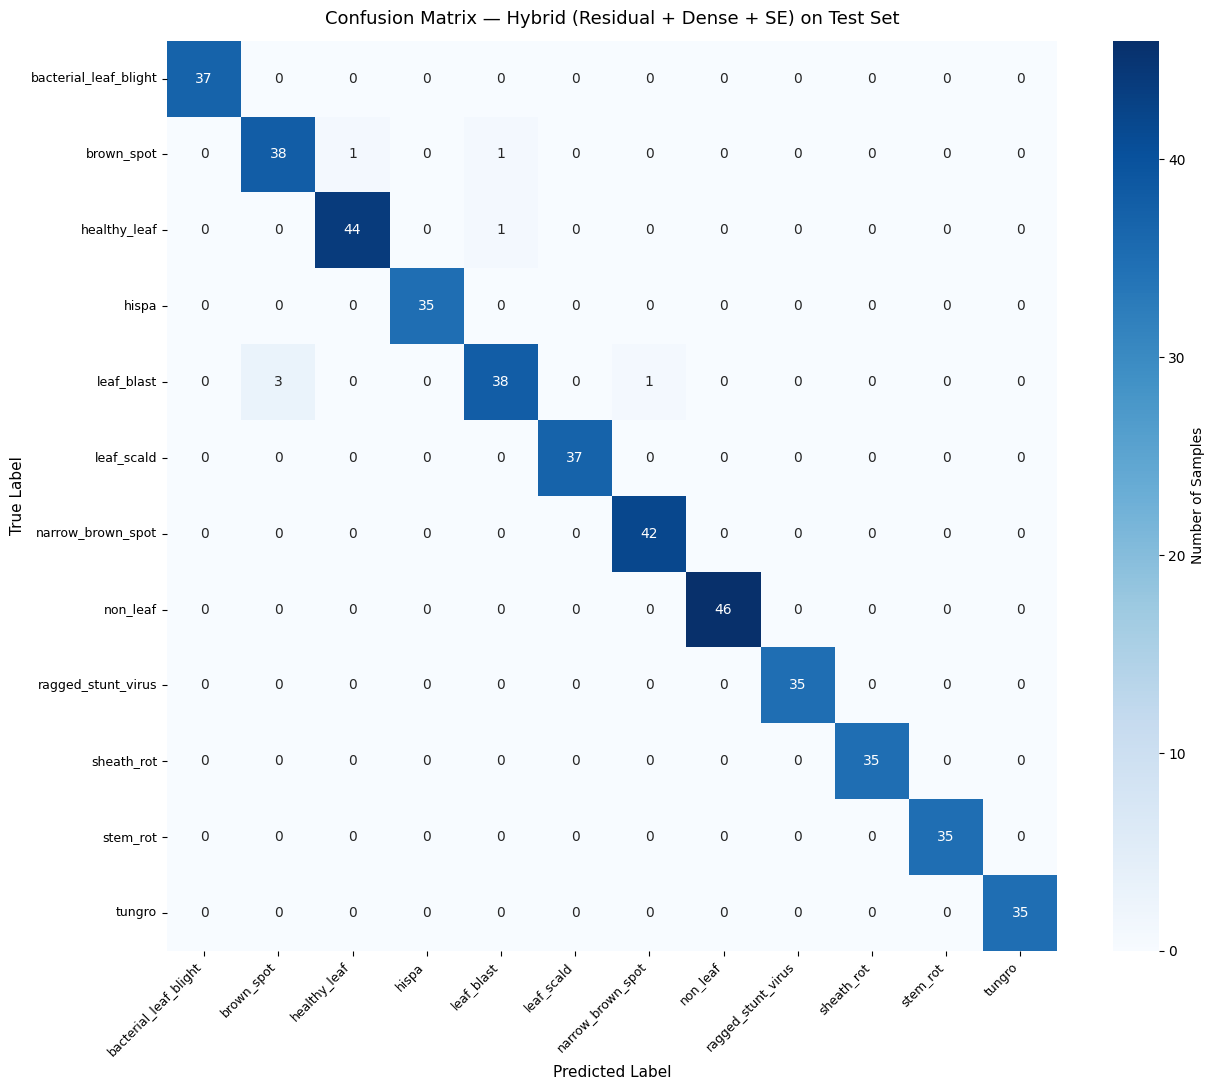


✅ Confusion matrix saved to: /content/drive/MyDrive/cm_hybrid_rds.png


In [17]:

# ==============================================================================
# EVALUATE ON TEST SET
# ==============================================================================
print("\n" + "=" * 78)
print("TEST SET EVALUATION")
print("=" * 78)

test_pred_probs = model.predict(test_generator, verbose=1)
test_pred = np.argmax(test_pred_probs, axis=1)
test_true = test_generator.classes

test_acc = accuracy_score(test_true, test_pred) * 100

print(f"\nTest Accuracy: {test_acc:.2f}%\n")
print("Classification Report:")
print(classification_report(test_true, test_pred, target_names=class_names, digits=4))

# ---- Confusion Matrix ----
cm = confusion_matrix(test_true, test_pred)

plt.figure(figsize=(13, 11))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
    cbar_kws={"label": "Number of Samples"}
)
plt.title("Confusion Matrix — Hybrid (Residual + Dense + SE) on Test Set",
          fontsize=13, pad=12)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(CM_SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✅ Confusion matrix saved to: {CM_SAVE_PATH}")


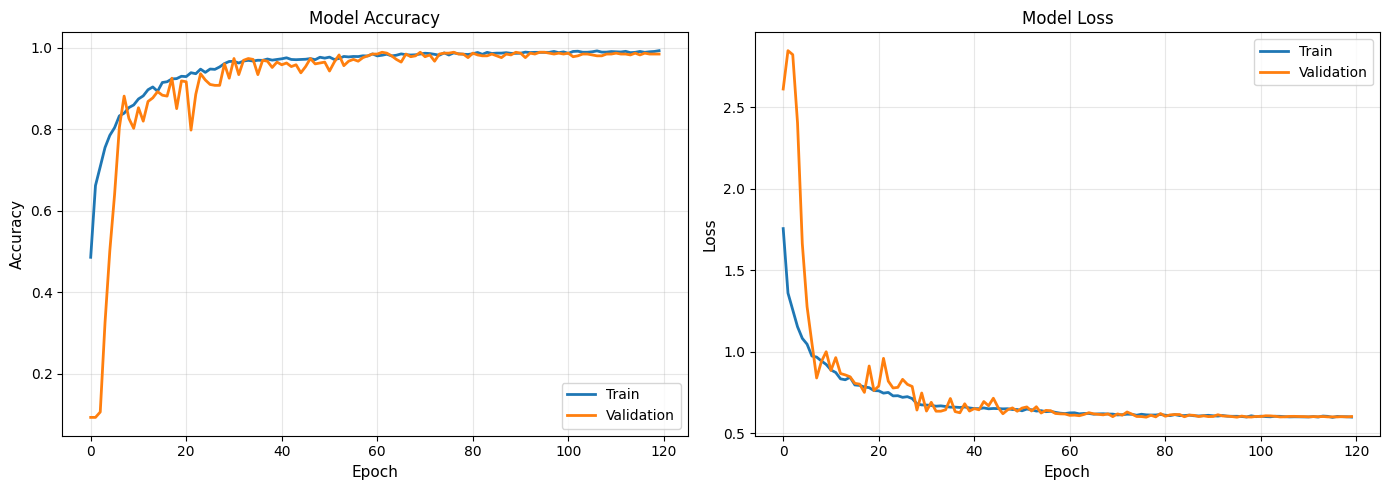

✅ Training curves saved to: /content/drive/MyDrive/curves_hybrid_rds.png


In [18]:

# ==============================================================================
# PLOT TRAINING CURVES
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"],     label="Train",      linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Validation", linewidth=2)
axes[0].set_xlabel("Epoch",    fontsize=11)
axes[0].set_ylabel("Accuracy", fontsize=11)
axes[0].set_title("Model Accuracy", fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history["loss"],     label="Train",      linewidth=2)
axes[1].plot(history.history["val_loss"], label="Validation", linewidth=2)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Loss",  fontsize=11)
axes[1].set_title("Model Loss", fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(CURVES_SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Training curves saved to: {CURVES_SAVE_PATH}")



In [19]:
# ==============================================================================
# SAVE EVALUATION RESULTS (JSON)
# ==============================================================================
results = {
    "test_accuracy": float(test_acc),
    "classification_report": classification_report(
        test_true, test_pred, target_names=class_names, output_dict=True
    ),
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
}
with open("/content/drive/MyDrive/results_hybrid_rds.json", "w") as f:
    json.dump(results, f, indent=2)

print("✅ Results JSON saved.")



✅ Results JSON saved.


In [20]:
# ==============================================================================
# FINAL SUMMARY
# ==============================================================================
print("\n" + "=" * 78)
print("FINAL SUMMARY — Hybrid (Residual + Dense + SE)")
print("=" * 78)
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Total Test Samples: {len(test_true)}")
print("=" * 78)


FINAL SUMMARY — Hybrid (Residual + Dense + SE)
Test Accuracy: 98.49%
Total Test Samples: 464
